In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:      
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)


try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path.cwd().resolve().parent
DATA = ROOT / "data"
FIG  = ROOT / "figures"
TAB  = ROOT / "reports" / "phase1" / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 10,
                     "axes.titlesize": 11, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
R = {}   
def save_tab(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df

In [2]:
uds = pd.read_csv(DATA / "udslong_imputed.csv")
mri = pd.read_csv(DATA / "mriscanclean.csv")

ids_u, ids_m = set(uds.NACCID), set(mri.NACCID)
flow = pd.DataFrame([
    ("UDS file: records",                         len(uds)),
    ("UDS file: unique participants (NACCID)",    uds.NACCID.nunique()),
    ("MRI file: records",                         len(mri)),
    ("MRI file: unique participants (NACCID)",    mri.NACCID.nunique()),
    ("Participants in both files",                len(ids_u & ids_m)),
    ("Only in UDS (no MRI match)",                len(ids_u - ids_m)),
    ("Only in MRI (no UDS match)",                len(ids_m - ids_u)),
    ("Duplicate NACCID in UDS / in MRI",          f"{uds.NACCID.duplicated().sum()} / {mri.NACCID.duplicated().sum()}"),
], columns=["step", "n"])
save_tab(flow, "table_linkage_flow")

chk = uds[["NACCID","NACCUDSD"]].merge(mri[["NACCID","NACCUDSD"]], on="NACCID", suffixes=("_uds","_mri"))
R["udsd_agree"] = bool((chk.NACCUDSD_uds == chk.NACCUDSD_mri).all())


df = uds.merge(mri.drop(columns="NACCUDSD"), on="NACCID", how="inner", validate="one_to_one")
R.update(n_uds=len(uds), n_mri=len(mri), n_merged=len(df), n_cols_uds=uds.shape[1], n_cols_mri=mri.shape[1])
print(flow.to_string(index=False)); print("NACCUDSD identical in both files:", R["udsd_agree"]); print("merged:", df.shape)

                                  step     n
                     UDS file: records  1237
UDS file: unique participants (NACCID)  1237
                     MRI file: records  1237
MRI file: unique participants (NACCID)  1237
            Participants in both files  1237
            Only in UDS (no MRI match)     0
            Only in MRI (no UDS match)     0
      Duplicate NACCID in UDS / in MRI 0 / 0
NACCUDSD identical in both files: True
merged: (1237, 304)


In [3]:
rows_per_id = uds.groupby("NACCID").size().value_counts().rename_axis("rows_per_participant").reset_index(name="n_participants")
save_tab(rows_per_id, "table_rows_per_participant")
print(rows_per_id)

   rows_per_participant  n_participants
0                     1            1237


In [4]:
DOMAINS = {
 ("demographic","demographics"): "SEX HISPANIC HISPOR RACE PRIMLANG EDUC MARISTAT NACCLIVS RESIDENC NACCNIHR NACCAGE",
 ("functional","independence / CDR / FAQ"): "INDEPEND BILLS TAXES SHOPPING GAMES STOVE MEALPREP EVENTS PAYATTN REMDATES TRAVEL MEMORY ORIENT JUDGMENT COMMUN HOMEHOBB PERSCARE CDRSUM CDRGLOB",
 ("cognitive","neuropsychological tests"): "DECSUB ANIMALS VEG TRAILA TRAILARR TRAILALI TRAILB TRAILBRR TRAILBLI MOCATOTS",
 ("diagnostic","cognitive status"): "NACCUDSD",
 ("medical","family history"): "NACCFAM NACCMOM NACCDAD NACCAM NACCAMS NACCFM NACCFMS NACCOM NACCOMS NACCFADM NACCFFTD",
 ("medical","genetic"): "NACCAPOE",
 ("medical","medications"): "ANYMEDS NACCAAAS NACCAANX NACCAC NACCACEI NACCADEP NACCAHTN NACCAMD NACCANGI NACCAPSY NACCBETA NACCCCBS NACCDBMD NACCDIUR NACCEMD NACCEPMD NACCHTNC NACCLIPL NACCNSD NACCPDMD NACCVASD",
 ("medical","substance use"): "TOBAC30 TOBAC100 SMOKYRS PACKSPER QUITSMOK ALCOHOL ABUSOTHR",
 ("medical","cardio/cerebrovascular"): "CVHATT CVAFIB CVANGIO CVBYPASS CVPACDEF CVCHF CVOTHR CBSTROKE CBTIA HYPERTEN HYPERCHO",
 ("medical","neurological"): "SEIZURES NACCTBI TBI TBIBRIEF TBIEXTEN TBIWOLOS NACCNREX NORMEXAM",
 ("medical","metabolic / other conditions"): "DIABETES DIABTYPE B12DEF THYROID ARTHRIT ARTHTYPE ARTHUPEX ARTHLOEX ARTHSPIN ARTHUNK INCONTU INCONTF APNEA RBD INSOMN OTHSLEEP",
 ("medical","psychiatric history"): "PTSD BIPOLAR SCHIZ DEP2YRS DEPOTHR ANXIETY OCD NPSYDEV PSYCDIS",
 ("medical","physical measures / sensory"): "HEIGHT WEIGHT BPSYS BPDIAS HRATE NACCBMI VISION VISCORR VISWCORR HEARING HEARAID HEARWAID",
 ("medical","behavioural symptoms (NPI-Q)"): "NPIQINF DEL DELSEV HALL HALLSEV AGIT AGITSEV DEPD DEPDSEV ANX ANXSEV ELAT ELATSEV APA APASEV DISN DISNSEV IRR IRRSEV MOT MOTSEV NITE NITESEV APP APPSEV",
 ("medical","mood (GDS)"): "NOGDS SATIS DROPACT EMPTY BORED SPIRITS AFRAID HAPPY HELPLESS STAYHOME MEMPROB WONDRFUL WRTHLESS ENERGY HOPELESS BETTER NACCGDS",
}
DESC = {
 "SEX":"Sex (1 male, 2 female)","HISPANIC":"Hispanic/Latino ethnicity","RACE":"Primary race","PRIMLANG":"Primary language",
 "EDUC":"Years of education (99 = unknown)","MARISTAT":"Marital status","NACCLIVS":"Living situation (1 alone, 2 spouse/partner, 3 relative/friend, 4 group, 5 other, 9 unknown)",
 "INDEPEND":"Level of independence","RESIDENC":"Type of residence","NACCAGE":"Age at visit (years)","NACCFAM":"Family history of cognitive impairment",
 "ANYMEDS":"Taking any medication","NACCAPOE":"APOE genotype","NACCBMI":"Body mass index","HEIGHT":"Height","WEIGHT":"Weight","BPSYS":"Systolic blood pressure",
 "BPDIAS":"Diastolic blood pressure","HRATE":"Resting heart rate","NACCGDS":"Geriatric Depression Scale total","MOCATOTS":"MoCA total score (0-30)",
 "TRAILA":"Trail Making Test Part A, seconds","TRAILB":"Trail Making Test Part B, seconds (executive function; higher = worse)",
 "TRAILARR":"Trails A: errors (verify in RDD)","TRAILALI":"Trails A: correct lines (verify in RDD)","TRAILBRR":"Trails B: errors (verify in RDD)","TRAILBLI":"Trails B: correct lines (verify in RDD)",
 "ANIMALS":"Category fluency: animals","VEG":"Category fluency: vegetables","DECSUB":"Subject reports memory decline",
 "CDRSUM":"CDR sum of boxes","CDRGLOB":"Global CDR","MEMORY":"CDR box: memory","ORIENT":"CDR box: orientation","JUDGMENT":"CDR box: judgment/problem solving",
 "COMMUN":"CDR box: community affairs","HOMEHOBB":"CDR box: home/hobbies","PERSCARE":"CDR box: personal care",
 "NACCUDSD":"Cognitive status at visit (1 normal, 2 impaired-not-MCI, 3 MCI, 4 dementia)",
}
dom_rows = []
for (dom, sub), names in DOMAINS.items():
    for v in names.split():
        dom_rows.append((v, dom, sub))
dom_df = pd.DataFrame(dom_rows, columns=["variable","domain","subdomain"])
assert dom_df.variable.is_unique
missing_in_map = set(uds.columns) - set(dom_df.variable) - {"NACCID"}
extra_in_map   = set(dom_df.variable) - set(uds.columns)
assert not missing_in_map and not extra_in_map, (missing_in_map, extra_in_map)

def infer_scale(s):
    s = s.dropna(); nu = s.nunique()
    if nu <= 2: return "binary"
    if (s % 1 != 0).any() or nu > 15: return "continuous / many values"
    return "categorical or discrete (<=15 values)"
vm = dom_df.copy()
vm["description"] = vm.variable.map(DESC).fillna("see RDD")
vm["n_unique"]    = [uds[v].nunique() for v in vm.variable]
vm["min"]         = [uds[v].min() for v in vm.variable]
vm["max"]         = [uds[v].max() for v in vm.variable]
vm["inferred_scale"] = [infer_scale(uds[v]) for v in vm.variable]
save_tab(vm, "variable_map_uds")
dom_counts = vm.groupby(["domain","subdomain"]).size().rename("n_variables").reset_index()
save_tab(dom_counts, "table_uds_domain_counts")
R["uds_domain_counts"] = vm.groupby("domain").size().to_dict()
print(dom_counts.to_string(index=False))

     domain                    subdomain  n_variables
  cognitive     neuropsychological tests           10
demographic                 demographics           11
 diagnostic             cognitive status            1
 functional     independence / CDR / FAQ           19
    medical behavioural symptoms (NPI-Q)           25
    medical       cardio/cerebrovascular           11
    medical               family history           11
    medical                      genetic            1
    medical                  medications           21
    medical metabolic / other conditions           16
    medical                   mood (GDS)           17
    medical                 neurological            8
    medical  physical measures / sensory           12
    medical          psychiatric history            9
    medical                substance use            7


In [5]:
LOBE = {}
for lobe, regs in {
 "frontal": "CAUDALMIDDLEFRONTAL LATERALORBITOFRONTAL MEDIALORBITOFRONTAL PARACENTRAL PARSOPERCULARIS PARSORBITALIS PARSTRIANGULARIS PRECENTRAL ROSTRALMIDDLEFRONTAL SUPERIORFRONTAL",
 "parietal": "INFERIORPARIETAL POSTCENTRAL PRECUNEUS SUPERIORPARIETAL SUPRAMARGINAL",
 "temporal": "ENTORHINAL FUSIFORM INFERIORTEMPORAL MIDDLETEMPORAL PARAHIPPOCAMPAL SUPERIORTEMPORAL TRANSVERSETEMPORAL",
 "occipital": "CUNEUS LATERALOCCIPITAL LINGUAL PERICALCARINE",
 "cingulate": "CAUDALANTERIORCINGULATE ISTHMUSCINGULATE POSTERIORCINGULATE ROSTRALANTERIORCINGULATE",
 "insula": "INSULA"}.items():
    for r in regs.split(): LOBE[r] = lobe
mri_cols = [c for c in mri.columns if c not in ("NACCID","NACCUDSD")]
mm = pd.DataFrame({"variable": mri_cols})
mm["hemisphere"] = mm.variable.str.split("_").str[0]
mm["measure"]    = mm.variable.str.rsplit("_", n=1).str[-1]
mm["region"]     = mm.variable.str.split("_", n=1).str[1].str.rsplit("_", n=1).str[0]
mm["lobe"]       = mm.region.map(LOBE)
assert mm.lobe.notna().all()
mm["meaning"]    = mm.measure.map({"GVOL":"gray-matter volume (mm^3)",
                                   "AVGTH":"average cortical thickness (mm)"})
save_tab(mm, "variable_map_mri")
R.update(n_mri_regions=int(mm.region.nunique()), n_mri_measures=int(mm.measure.nunique()), n_mri_vars=len(mm))
print(mm.groupby(["lobe","measure"]).size().unstack())

measure    AVGTH  GVOL
lobe                  
cingulate      8     8
frontal       20    20
insula         2     2
occipital      8     8
parietal      10    10
temporal      14    14


In [6]:
FRONT = ["CAUDALMIDDLEFRONTAL","ROSTRALMIDDLEFRONTAL","SUPERIORFRONTAL"]
FRONT_COLS = [f"{h}_{r}_AVGTH" for h in ("LH","RH") for r in FRONT]
main_vars = pd.DataFrame([
 ("NACCLIVS","UDS","Living situation","Nominal (categorical, 4 usable groups)","Main explanatory / grouping variable","Frequency table, bar chart; ANOVA/chi-square family later"),
 ("TRAILB","UDS","Trail Making B time (s)","Quantitative continuous (ratio); right-skewed, capped at 300 s, special codes","Cognitive response (executive function)","Median/IQR, boxplot, log scale"),
 ("NACCAGE","UDS","Age (years)","Quantitative continuous","Adjusting variable / sample definition (>=65)","Mean/SD or median/IQR, histogram"),
 ("SEX","UDS","Sex","Binary","Adjusting variable","Frequency table"),
 ("EDUC","UDS","Years of education","Quantitative discrete","Adjusting variable","Median/IQR (ceiling near 16-20 years)"),
 ("FRONTAL_THK","MRI (derived)","Mean AVGTH of 6 frontal values (caudal/rostral middle frontal, superior frontal; LH+RH), mm","Quantitative continuous","Imaging response","Mean/SD, histogram, boxplot"),
], columns=["variable","source","meaning","type / scale","role (from PROJECT_CARD)","summary / plot choice"])
save_tab(main_vars, "table_main_variables")
main_vars[["variable","type / scale","role (from PROJECT_CARD)"]]

,variable,type / scale,role (from PROJECT_CARD)
0,NACCLIVS,"Nominal (categorical, 4 usable groups)",Main explanatory / grouping variable
1,TRAILB,"Quantitative continuous (ratio); right-skewed,...",Cognitive response (executive function)
2,NACCAGE,Quantitative continuous,Adjusting variable / sample definition (>=65)
3,SEX,Binary,Adjusting variable
4,EDUC,Quantitative discrete,Adjusting variable
5,FRONTAL_THK,Quantitative continuous,Imaging response


In [7]:
R["nan_uds"] = int(uds.isna().sum().sum()); R["nan_mri"] = int(mri.isna().sum().sum())
print("NaN cells  UDS:", R["nan_uds"], " MRI:", R["nan_mri"])



EXPECT = {
 "SEX":(1,2,[],True), "EDUC":(0,36,[99],True), "NACCAGE":(18,110,[],True), "NACCLIVS":(1,5,[9],True),
 "MARISTAT":(1,6,[9],True), "NACCUDSD":(1,4,[],True), "TRAILB":(0,300,[995,996,997,998],True),
 "TRAILA":(0,150,[995,996,997,998],True), "MOCATOTS":(0,30,[88],True), "NACCAPOE":(1,6,[9],True),
}
rows = []
for v,(lo,hi,codes,integ) in EXPECT.items():
    s = uds[v]
    is_code = s.isin(codes)
    frac = s.notna() & (s % 1 != 0)
    out = s.notna() & ~is_code & ~frac & ((s < lo) | (s > hi))
    out_imp = frac & ((s < lo) | (s > hi))
    rows.append({"variable":v, "expected_range":f"{lo}-{hi}", "special_codes":str(codes) if codes else "-",
                 "n_nan":int(s.isna().sum()), "n_special_code":int(is_code.sum()),
                 "n_non_integer(imputed?)":int(frac.sum()), "n_non_integer_out_of_range":int(out_imp.sum()),
                 "n_integer_out_of_range":int(out.sum())})
audit_vars = pd.DataFrame(rows)
save_tab(audit_vars, "table_audit_main_variables")
print(audit_vars.to_string(index=False))

NaN cells  UDS: 0  MRI: 0
variable expected_range        special_codes  n_nan  n_special_code  n_non_integer(imputed?)  n_non_integer_out_of_range  n_integer_out_of_range
     SEX            1-2                    -      0               0                        0                           0                       0
    EDUC           0-36                 [99]      0               2                        0                           0                       0
 NACCAGE         18-110                    -      0               0                        0                           0                       0
NACCLIVS            1-5                  [9]      0               3                        0                           0                       0
MARISTAT            1-6                  [9]      0               3                        0                           0                       0
NACCUDSD            1-4                    -      0               0                        0            

In [8]:
def classify_trail(s, vmax, codes=(995,996,997,998)):
    """observed (integer within range) | observed_at_cap | special_code | imputed_in_range |
       imputed_out_of_range | integer_out_of_range | missing"""
    out = pd.Series("observed", index=s.index, dtype=object)
    frac = s.notna() & (s % 1 != 0)
    out[s.isna()] = "missing"
    out[s.isin(codes)] = "special_code"
    out[frac & (s <= vmax)] = "imputed_in_range"
    out[frac & (s > vmax)]  = "imputed_out_of_range"
    out[(~frac) & s.notna() & ~s.isin(codes) & (s > vmax)] = "integer_out_of_range"
    out[(out == "observed") & (s == vmax)] = "observed_at_cap"
    return out
uds["TRAILB_class"] = classify_trail(uds.TRAILB, 300)
uds["TRAILA_class"] = classify_trail(uds.TRAILA, 150)
tcls = pd.concat({"TRAILB": uds.TRAILB_class.value_counts(), "TRAILA": uds.TRAILA_class.value_counts()}, axis=1).fillna(0).astype(int)
tcls["TRAILB_pct"] = (100*tcls.TRAILB/len(uds)).round(1); tcls["TRAILA_pct"] = (100*tcls.TRAILA/len(uds)).round(1)
save_tab(tcls, "table_trail_value_classes", index=True)
print(tcls)

                      TRAILB  TRAILA  TRAILB_pct  TRAILA_pct
observed                1079    1152        87.2        93.1
observed_at_cap           55      15         4.4         1.2
special_code              55      21         4.4         1.7
imputed_in_range          39      44         3.2         3.6
imputed_out_of_range       9       4         0.7         0.3
integer_out_of_range       0       1         0.0         0.1


C:\Users\RSKALA.COM\AppData\Local\Temp\ipykernel_27792\3207148041.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds["TRAILB_class"] = classify_trail(uds.TRAILB, 300)
C:\Users\RSKALA.COM\AppData\Local\Temp\ipykernel_27792\3207148041.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds["TRAILA_class"] = classify_trail(uds.TRAILA, 150)


In [9]:
X = uds.drop(columns=["NACCID","TRAILB_class","TRAILA_class"])
frac_cells = X.notna() & (X % 1 != 0)
for v in ["NACCBMI","HEIGHT"]: frac_cells[v] = False
for v in ["CDRSUM","CDRGLOB"]: frac_cells[v] = X[v].notna() & ((X[v]*2) % 1 != 0)
imp = pd.DataFrame({"variable": X.columns, "n_non_integer": frac_cells.sum().values})
imp = imp[imp.n_non_integer > 0].merge(vm[["variable","domain","subdomain"]], on="variable").sort_values("n_non_integer", ascending=False)
imp["pct_of_rows"] = (100*imp.n_non_integer/len(uds)).round(1)
save_tab(imp, "table_suspected_imputed_columns")
R.update(n_imputed_cols=int(len(imp)), n_imputed_cells=int(frac_cells.values.sum()),
         n_part_with_imputed=int(frac_cells.any(axis=1).sum()))
print(R["n_imputed_cols"], "columns;", R["n_imputed_cells"], "cells;", R["n_part_with_imputed"], "participants with >=1")
imp.head(12)

137 columns; 5311 cells; 753 participants with >=1


,variable,n_non_integer,domain,subdomain,pct_of_rows
132,MEMORY,264,functional,independence / CDR / FAQ,21.3
131,MOCATOTS,249,cognitive,neuropsychological tests,20.1
31,ARTHRIT,247,medical,metabolic / other conditions,20.0
32,ARTHTYPE,233,medical,metabolic / other conditions,18.8
33,ARTHUPEX,228,medical,metabolic / other conditions,18.4
34,ARTHLOEX,216,medical,metabolic / other conditions,17.5
134,JUDGMENT,206,functional,independence / CDR / FAQ,16.7
35,ARTHSPIN,187,medical,metabolic / other conditions,15.1
39,APNEA,174,medical,metabolic / other conditions,14.1
21,TBI,164,medical,neurological,13.3


In [10]:
chk_rows = []
def add(name, mask, comment):
    chk_rows.append({"check": name, "n": int(mask.sum()), "comment": comment})
add("NACCUDSD = 1 (normal) and CDRGLOB >= 1", (uds.NACCUDSD==1)&(uds.CDRGLOB>=1), "contradictory")
add("NACCUDSD = 4 (dementia) and CDRGLOB = 0", (uds.NACCUDSD==4)&(uds.CDRGLOB==0), "contradictory")
add("NACCUDSD = 1 (normal) and CDRGLOB = 0.5", (uds.NACCUDSD==1)&(uds.CDRGLOB==0.5), "possible (clinician judgement), not an error")
add("NACCLIVS = 1 (alone) and MARISTAT in {married, domestic partner}", (uds.NACCLIVS==1)&uds.MARISTAT.isin([1,6]), "plausible (partner lives elsewhere); flagged")
add("NACCLIVS = 2 (spouse/partner) and MARISTAT in {widowed, divorced, never married}", (uds.NACCLIVS==2)&uds.MARISTAT.isin([2,3,5]), "plausible (unmarried partner); flagged")
ok = uds.TRAILA_class.isin(["observed","observed_at_cap"]) & uds.TRAILB_class.isin(["observed","observed_at_cap"])
add("TRAILB < TRAILA (both observed)", ok & (uds.TRAILB < uds.TRAILA), "unusual (part B is normally slower)")
add("EDUC (valid) > NACCAGE - 3", uds.EDUC.between(0,36) & (uds.EDUC > uds.NACCAGE-3), "impossible")
add("NACCAGE < 18 or > 110", (uds.NACCAGE<18)|(uds.NACCAGE>110), "impossible")
logic = save_tab(pd.DataFrame(chk_rows), "table_logic_checks")
print(logic.to_string(index=False))

                                                                           check  n                                      comment
                                          NACCUDSD = 1 (normal) and CDRGLOB >= 1  0                                contradictory
                                         NACCUDSD = 4 (dementia) and CDRGLOB = 0  0                                contradictory
                                         NACCUDSD = 1 (normal) and CDRGLOB = 0.5 75 possible (clinician judgement), not an error
                NACCLIVS = 1 (alone) and MARISTAT in {married, domestic partner} 17 plausible (partner lives elsewhere); flagged
NACCLIVS = 2 (spouse/partner) and MARISTAT in {widowed, divorced, never married} 14       plausible (unmarried partner); flagged
                                                 TRAILB < TRAILA (both observed)  2          unusual (part B is normally slower)
                                                      EDUC (valid) > NACCAGE - 3  0              

In [11]:
gv = mri.filter(like="_GVOL"); th = mri.filter(like="_AVGTH")
R["mri_gvol_le0"] = int((gv <= 0).sum().sum()); R["mri_gvol_zero_cols"] = (gv <= 0).sum()[(gv <= 0).sum() > 0].to_dict()
R["mri_th_lt1_cells"] = int((th < 1.0).sum().sum()); R["mri_th_lt1_part"] = int((th < 1.0).any(axis=1).sum())
R["mri_th_min"] = float(th.min().min()); R["mri_th_max"] = float(th.max().max())
fr = mri[FRONT_COLS]
R["front_lt1_cells"] = int((fr < 1.0).sum().sum()); R["front_lt1_part"] = int((fr < 1.0).any(axis=1).sum())
mri_audit = fr.describe().T[["count","mean","std","min","50%","max"]].round(3)
mri_audit["n_lt_1mm"] = (fr < 1.0).sum()
save_tab(mri_audit.reset_index().rename(columns={"index":"variable"}), "table_audit_frontal_regions")
print("GVOL <= 0:", R["mri_gvol_le0"], R["mri_gvol_zero_cols"]); print("AVGTH < 1 mm (all regions):", R["mri_th_lt1_cells"], "cells /", R["mri_th_lt1_part"], "participants")
print("frontal six: ", R["front_lt1_cells"], "cells /", R["front_lt1_part"], "participants"); mri_audit

GVOL <= 0: 2 {'LH_ENTORHINAL_GVOL': 1, 'LH_POSTERIORCINGULATE_GVOL': 1}
AVGTH < 1 mm (all regions): 58 cells / 6 participants
frontal six:  7 cells / 3 participants


,count,mean,std,min,50%,max,n_lt_1mm
LH_CAUDALMIDDLEFRONTAL_AVGTH,1237.0,2.404,0.158,0.880,2.421,2.830,1
LH_ROSTRALMIDDLEFRONTAL_AVGTH,1237.0,2.280,0.125,1.456,2.283,2.798,0
LH_SUPERIORFRONTAL_AVGTH,1237.0,2.492,0.145,1.026,2.497,2.903,0
RH_CAUDALMIDDLEFRONTAL_AVGTH,1237.0,2.389,0.160,0.772,2.401,2.810,3
RH_ROSTRALMIDDLEFRONTAL_AVGTH,1237.0,2.254,0.149,0.746,2.257,3.064,3
RH_SUPERIORFRONTAL_AVGTH,1237.0,2.471,0.136,1.119,2.478,2.912,0


In [12]:
d = df.copy()
d["TRAILB_class"] = uds.set_index("NACCID").loc[d.NACCID, "TRAILB_class"].values
d["SEX_lbl"]   = d.SEX.map({1:"Male", 2:"Female"})
d["EDUC_c"]    = d.EDUC.where(d.EDUC.between(0, 36))
d["LIVS"]      = d.NACCLIVS.where(d.NACCLIVS.isin([1,2,3,4,5]))
GROUPS = ["Alone", "Spouse/partner", "Relative/friend", "Group"]
d["LIV_grp"]   = d.NACCLIVS.map({1:"Alone", 2:"Spouse/partner", 3:"Relative/friend", 4:"Group"})
d["DX"]        = d.NACCUDSD.map({1:"Normal", 2:"Impaired-not-MCI", 3:"MCI", 4:"Dementia"})
d["TRAILB_obs"]           = d.TRAILB.where(d.TRAILB_class.isin(["observed","observed_at_cap"]))
d["TRAILB_incl_imputed"]  = d.TRAILB.where(d.TRAILB_class.isin(["observed","observed_at_cap","imputed_in_range"]))
d["TRAILB_at_cap"]        = (d.TRAILB_obs == 300)
d["FRONTAL_THK"]          = d[FRONT_COLS].mean(axis=1)
d["FRONTAL_LH"]           = d[[c for c in FRONT_COLS if c.startswith("LH")]].mean(axis=1)
d["FRONTAL_RH"]           = d[[c for c in FRONT_COLS if c.startswith("RH")]].mean(axis=1)
d["FRONTAL_flag_lt1mm"]   = (d[FRONT_COLS] < 1.0).any(axis=1)


steps = []
s0 = d; steps.append(("Linked participants (UDS + MRI)", len(s0)))
s1 = s0[s0.NACCAGE >= 65]; steps.append(("Age >= 65", len(s1)))
s2 = s1[s1.NACCLIVS.isin([1,2,3,4,5,9])]; 
s3 = s1[s1.NACCLIVS.isin([1,2,3,4])];      steps.append(("Valid NACCLIVS in {1,2,3,4}  (analytic sample A)", len(s3)))
A = s3.copy()
steps += [("   A with observed TRAILB (primary definition)", int(A.TRAILB_obs.notna().sum())),
          ("   A with TRAILB incl. imputed in-range values (sensitivity)", int(A.TRAILB_incl_imputed.notna().sum())),
          ("   A with frontal thickness (all 6 regions)", int(A.FRONTAL_THK.notna().sum())),
          ("   A with valid SEX, EDUC and age", int(A[["SEX","EDUC_c","NACCAGE"]].notna().all(axis=1).sum())),
          ("   A with TRAILB (primary) + thickness + SEX/EDUC/age (complete case)", int(A[["TRAILB_obs","FRONTAL_THK","SEX","EDUC_c","NACCAGE"]].notna().all(axis=1).sum()))]
exc = pd.DataFrame({"reason":["Age < 65","NACCLIVS = 5 (other, n too small)","NACCLIVS = 9 (unknown)"],
                    "n_excluded":[int((d.NACCAGE<65).sum()),
                                  int(((d.NACCAGE>=65)&(d.NACCLIVS==5)).sum()),
                                  int(((d.NACCAGE>=65)&(d.NACCLIVS==9)).sum())]})
sflow = save_tab(pd.DataFrame(steps, columns=["step","n"]), "table_sample_flow")
save_tab(exc, "table_exclusions")
R.update(n_A=len(A), n_age65=len(s1), n_age_lt65=int((d.NACCAGE<65).sum()), age_min=float(d.NACCAGE.min()), age_max=float(d.NACCAGE.max()),
         n_A_trailb=int(A.TRAILB_obs.notna().sum()), n_A_trailb_imp=int(A.TRAILB_incl_imputed.notna().sum()),
         n_A_thk=int(A.FRONTAL_THK.notna().sum()), n_A_complete=int(A[["TRAILB_obs","FRONTAL_THK","SEX","EDUC_c","NACCAGE"]].notna().all(axis=1).sum()))
print(sflow.to_string(index=False)); print(exc.to_string(index=False))

                                                                 step    n
                                      Linked participants (UDS + MRI) 1237
                                                            Age >= 65  864
                     Valid NACCLIVS in {1,2,3,4}  (analytic sample A)  861
                          A with observed TRAILB (primary definition)  798
            A with TRAILB incl. imputed in-range values (sensitivity)  821
                             A with frontal thickness (all 6 regions)  861
                                       A with valid SEX, EDUC and age  860
   A with TRAILB (primary) + thickness + SEX/EDUC/age (complete case)  797
                           reason  n_excluded
                         Age < 65         373
NACCLIVS = 5 (other, n too small)           1
           NACCLIVS = 9 (unknown)           2


In [13]:
a_cls = A.TRAILB_class.value_counts().rename("n").to_frame(); a_cls["pct"] = (100*a_cls.n/len(A)).round(1)
save_tab(a_cls, "table_trailb_classes_sampleA", index=True)
R["trailb_classes_A"] = a_cls.n.to_dict(); R["trailb_at_cap_A"] = int(A.TRAILB_at_cap.sum())
print(a_cls)

R["front_lh_rh_r"] = float(A[["FRONTAL_LH","FRONTAL_RH"]].corr().iloc[0,1])
R["front_flag_A"] = int(A.FRONTAL_flag_lt1mm.sum())
print("r(LH,RH frontal mean):", round(R["front_lh_rh_r"],2), "| participants in A with a frontal value < 1 mm:", R["front_flag_A"])

                        n   pct
TRAILB_class                   
observed              752  87.3
observed_at_cap        46   5.3
special_code           34   3.9
imputed_in_range       23   2.7
imputed_out_of_range    6   0.7
r(LH,RH frontal mean): 0.85 | participants in A with a frontal value < 1 mm: 2


In [14]:
dec = pd.DataFrame([
 ("Special codes (EDUC 99, NACCLIVS 9, TRAILB/TRAILA 995-998)", "n per variable: see table_audit_main_variables", "Recode to NaN on a working copy", "These are 'unknown/not done' codes, not measurements; averaging them would be meaningless."),
 ("Non-integer (suspected imputed) TRAILB/TRAILA values", f"TRAILB: {int((uds.TRAILB_class.isin(['imputed_in_range','imputed_out_of_range'])).sum())} values", "Excluded from primary TRAILB; kept in sensitivity definition (in-range only)", "Imputation method unknown; values > 300 s are impossible for this test."),
 ("TRAILB = 300 s", f"{int((uds.TRAILB_class=='observed_at_cap').sum())} participants", "Kept; flagged as censored at the time limit", "True time is >= 300 s; Phase 3/4 will check sensitivity (e.g. log scale, rank methods)."),
 ("Other suspected imputed columns", f"{R['n_imputed_cols']} columns, {R['n_imputed_cells']} cells", "Not used in the main question; documented only", "Variables are outside the analysis plan; ask teaching team about imputation method."),
 ("MRI thickness < 1 mm in a frontal region", f"{R['front_lt1_cells']} cells / {R['front_lt1_part']} participants", "Kept and flagged (FRONTAL_flag_lt1mm); influence checked in Phase 4/5", "Biologically unlikely (likely segmentation error) but no rule allows silent deletion."),
 ("MRI volume = 0", f"{R['mri_gvol_le0']} cells", "Kept; not used in the main question", "Volumes are not part of the analysis plan."),
 ("Duplicate NACCID", "0", "None needed", "One record per participant in both files."),
 ("Logical inconsistencies", "see table_logic_checks", "No row removed; flagged items are plausible", "No contradictory NACCUDSD/CDR or impossible age/education combinations."),
], columns=["problem","how many","decision","reason"])
save_tab(dec, "table_data_decisions")
dec

,problem,how many,decision,reason
0,"Special codes (EDUC 99, NACCLIVS 9, TRAILB/TRA...",n per variable: see table_audit_main_variables,Recode to NaN on a working copy,"These are 'unknown/not done' codes, not measur..."
1,Non-integer (suspected imputed) TRAILB/TRAILA ...,TRAILB: 48 values,Excluded from primary TRAILB; kept in sensitiv...,Imputation method unknown; values > 300 s are ...
2,TRAILB = 300 s,55 participants,Kept; flagged as censored at the time limit,True time is >= 300 s; Phase 3/4 will check se...
3,Other suspected imputed columns,"137 columns, 5311 cells",Not used in the main question; documented only,Variables are outside the analysis plan; ask t...
4,MRI thickness < 1 mm in a frontal region,7 cells / 3 participants,Kept and flagged (FRONTAL_flag_lt1mm); influen...,Biologically unlikely (likely segmentation err...
5,MRI volume = 0,2 cells,Kept; not used in the main question,Volumes are not part of the analysis plan.
6,Duplicate NACCID,0,None needed,One record per participant in both files.
7,Logical inconsistencies,see table_logic_checks,No row removed; flagged items are plausible,No contradictory NACCUDSD/CDR or impossible ag...


In [15]:
def unavailable_pct(mask, n): return round(100*mask.sum()/n, 1)
def miss_table(S, label):
    n = len(S)
    rows = [
     ("NACCLIVS (valid code 1-5)", ((S.NACCLIVS==9)|S.NACCLIVS.isna())),
     ("NACCAGE", S.NACCAGE.isna()), ("SEX", S.SEX.isna()), ("EDUC (99 = unknown)", S.EDUC_c.isna()),
     ("TRAILB (primary: observed only)", S.TRAILB_obs.isna()),
     ("TRAILB (incl. in-range imputed)", S.TRAILB_incl_imputed.isna()),
     ("Frontal thickness (6 regions)", S.FRONTAL_THK.isna()),
     ("All 124 MRI columns (any NaN)", S[mri_cols].isna().any(axis=1)),
    ]
    return pd.DataFrame([{"variable":v, f"n_unavailable_{label}": int(m.sum()), f"pct_{label}": unavailable_pct(m, n)} for v,m in rows])
mt = miss_table(d, "all").merge(miss_table(A, "A"), on="variable")
save_tab(mt, "table_missingness_main")
print(mt.to_string(index=False))

                       variable  n_unavailable_all  pct_all  n_unavailable_A  pct_A
      NACCLIVS (valid code 1-5)                  3      0.2                0    0.0
                        NACCAGE                  0      0.0                0    0.0
                            SEX                  0      0.0                0    0.0
            EDUC (99 = unknown)                  2      0.2                1    0.1
TRAILB (primary: observed only)                103      8.3               63    7.3
TRAILB (incl. in-range imputed)                 64      5.2               40    4.6
  Frontal thickness (6 regions)                  0      0.0                0    0.0
  All 124 MRI columns (any NaN)                  0      0.0                0    0.0


In [16]:
A = A.assign(TRAILB_status=np.where(A.TRAILB_obs.notna(), "TRAILB usable", "TRAILB not usable"))
def prof(g):
    return pd.Series({"n": len(g), "age_mean": g.NACCAGE.mean(), "age_sd": g.NACCAGE.std(),
                      "pct_female": 100*(g.SEX==2).mean(), "educ_median": g.EDUC_c.median(),
                      "pct_alone": 100*(g.LIV_grp=="Alone").mean(), "pct_MCI": 100*(g.NACCUDSD==3).mean(),
                      "pct_dementia": 100*(g.NACCUDSD==4).mean(), "frontal_thk_mean": g.FRONTAL_THK.mean()})
sel = A.groupby("TRAILB_status").apply(prof).round(2)
save_tab(sel.reset_index(), "table_selection_trailb_usable")
print(sel.T)

TRAILB_status     TRAILB not usable  TRAILB usable
n                             63.00         798.00
age_mean                      72.73          72.19
age_sd                         5.58           5.29
pct_female                    60.32          56.89
educ_median                   16.00          16.00
pct_alone                     15.87          23.18
pct_MCI                       26.98          23.31
pct_dementia                  44.44           7.52
frontal_thk_mean               2.36           2.38


In [17]:
def freq(s, name, order=None):
    t = s.value_counts(dropna=False)
    if order is not None: t = t.reindex(order + [i for i in t.index if i not in order])
    out = t.rename("n").to_frame(); out["pct"] = (100*out.n/out.n.sum()).round(1)
    out.insert(0, "variable", name); out.index.name = "category"
    return out.reset_index()
ms_lbl = {1:"Married",2:"Widowed",3:"Divorced",4:"Separated",5:"Never married",6:"Living as married",9:"Unknown"}
ft = pd.concat([
    freq(d.NACCLIVS.map({1:"1 Alone",2:"2 Spouse/partner",3:"3 Relative/friend",4:"4 Group",5:"5 Other",9:"9 Unknown"}), "NACCLIVS (all 1,237)"),
    freq(A.LIV_grp, "NACCLIVS (sample A)", GROUPS),
    freq(A.SEX_lbl, "SEX (sample A)", ["Female","Male"]),
    freq(A.DX, "NACCUDSD (sample A)", ["Normal","Impaired-not-MCI","MCI","Dementia"]),
    freq(A.MARISTAT.map(ms_lbl), "MARISTAT (sample A)"),
    freq(d.DX, "NACCUDSD (all 1,237)", ["Normal","Impaired-not-MCI","MCI","Dementia"]),
])
save_tab(ft, "table_frequencies")
print(ft.to_string(index=False))

         category             variable   n  pct
 2 Spouse/partner NACCLIVS (all 1,237) 827 66.9
          1 Alone NACCLIVS (all 1,237) 254 20.5
3 Relative/friend NACCLIVS (all 1,237)  82  6.6
          4 Group NACCLIVS (all 1,237)  70  5.7
        9 Unknown NACCLIVS (all 1,237)   3  0.2
          5 Other NACCLIVS (all 1,237)   1  0.1
            Alone  NACCLIVS (sample A) 195 22.6
   Spouse/partner  NACCLIVS (sample A) 574 66.7
  Relative/friend  NACCLIVS (sample A)  56  6.5
            Group  NACCLIVS (sample A)  36  4.2
           Female       SEX (sample A) 492 57.1
             Male       SEX (sample A) 369 42.9
           Normal  NACCUDSD (sample A) 564 65.5
 Impaired-not-MCI  NACCUDSD (sample A)   6  0.7
              MCI  NACCUDSD (sample A) 203 23.6
         Dementia  NACCUDSD (sample A)  88 10.2
          Married  MARISTAT (sample A) 583 67.7
         Divorced  MARISTAT (sample A) 112 13.0
          Widowed  MARISTAT (sample A)  91 10.6
    Never married  MARISTAT (sample A)  

In [18]:
def qsummary(s):
    s0 = s; s = s.dropna(); q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    return pd.Series({"n": len(s), "n_unavailable": int(s0.isna().sum()), "mean": s.mean(), "sd": s.std(), "min": s.min(), "Q1": q1,
                      "median": s.median(), "Q3": q3, "max": s.max(), "IQR": iqr, "skewness": stats.skew(s, bias=False),
                      "n_outliers_1.5IQR": int(((s<lo)|(s>hi)).sum())})
A["log10_TRAILB"] = np.log10(A.TRAILB_obs)
qv = {"Age (years)":A.NACCAGE, "Education (years)":A.EDUC_c, "TRAILB, observed (s)":A.TRAILB_obs,
      "log10 TRAILB":A.log10_TRAILB, "Frontal thickness (mm)":A.FRONTAL_THK,
      "Frontal thickness LH (mm)":A.FRONTAL_LH, "Frontal thickness RH (mm)":A.FRONTAL_RH}
qs = pd.DataFrame({k: qsummary(v) for k, v in qv.items()}).T
qs.insert(0, "variable", qs.index)
save_tab(qs.round(3), "table_quantitative_summary")
R["qs"] = qs.drop(columns="variable").round(3).to_dict(orient="index")
qs.round(2)

,variable,n,n_unavailable,mean,sd,min,Q1,median,Q3,max,IQR,skewness,n_outliers_1.5IQR
Age (years),Age (years),861.0,0.0,72.23,5.31,65.00,68.00,71.00,76.00,91.00,8.00,0.69,6.0
Education (years),Education (years),860.0,1.0,16.22,2.89,0.00,14.00,16.00,18.00,25.00,4.00,-1.04,12.0
"TRAILB, observed (s)","TRAILB, observed (s)",798.0,63.0,102.34,63.51,28.00,63.00,82.00,113.75,300.00,50.75,1.97,69.0
log10 TRAILB,log10 TRAILB,798.0,63.0,1.95,0.22,1.45,1.80,1.91,2.06,2.48,0.26,0.77,49.0
Frontal thickness (mm),Frontal thickness (mm),861.0,0.0,2.38,0.12,1.04,2.32,2.39,2.45,2.80,0.14,-2.52,16.0
Frontal thickness LH (mm),Frontal thickness LH (mm),861.0,0.0,2.39,0.13,1.19,2.32,2.40,2.46,2.84,0.14,-1.93,16.0
Frontal thickness RH (mm),Frontal thickness RH (mm),861.0,0.0,2.37,0.13,0.88,2.31,2.38,2.44,2.75,0.14,-3.04,17.0


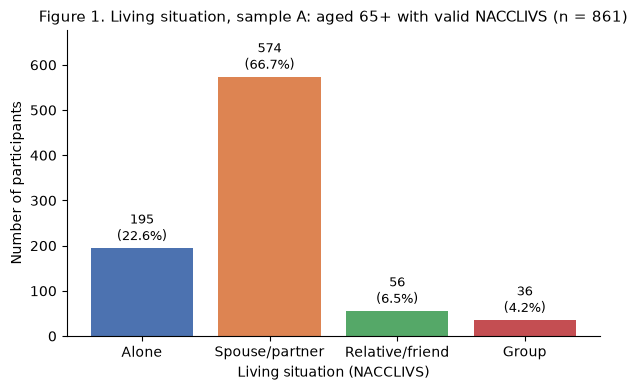

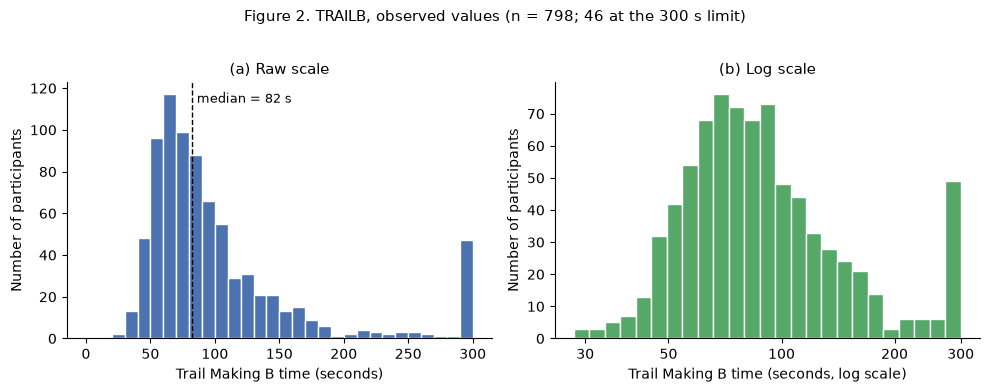

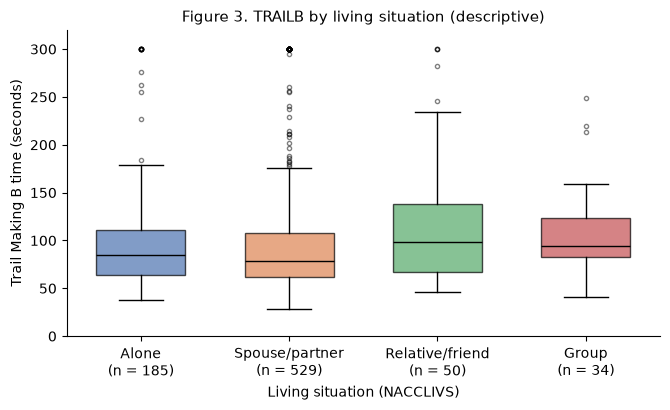

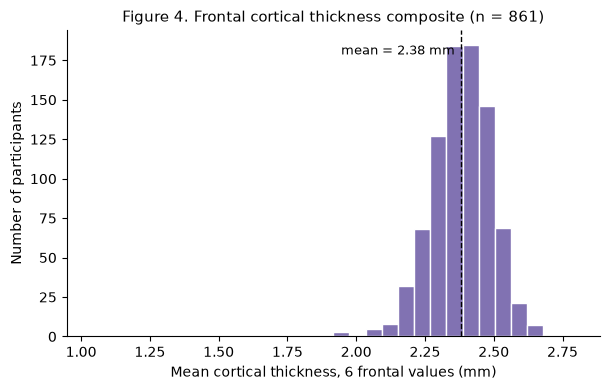

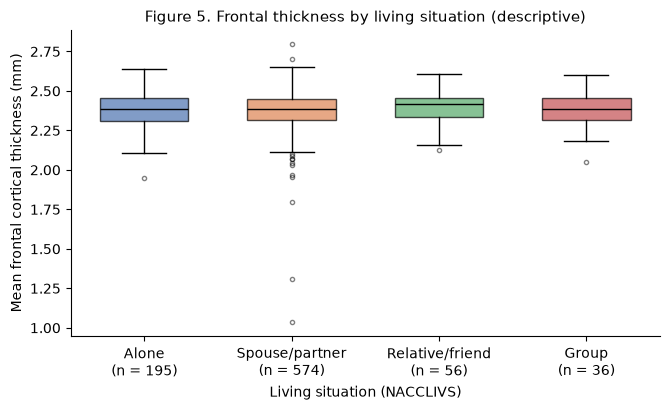

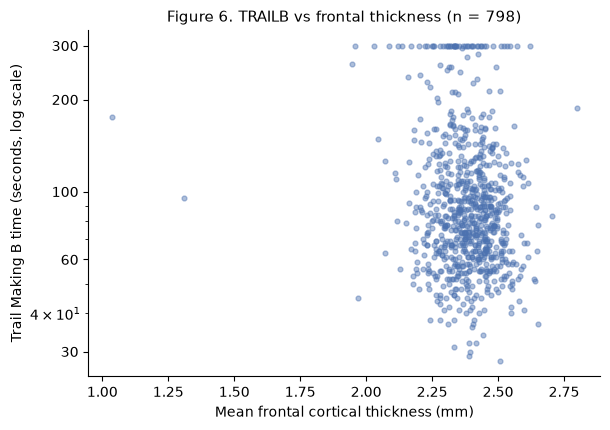

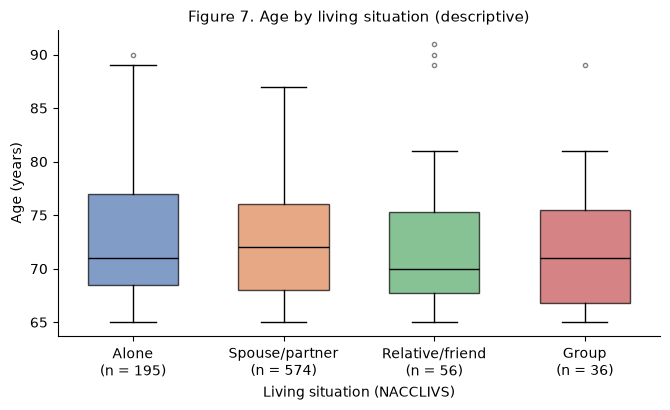

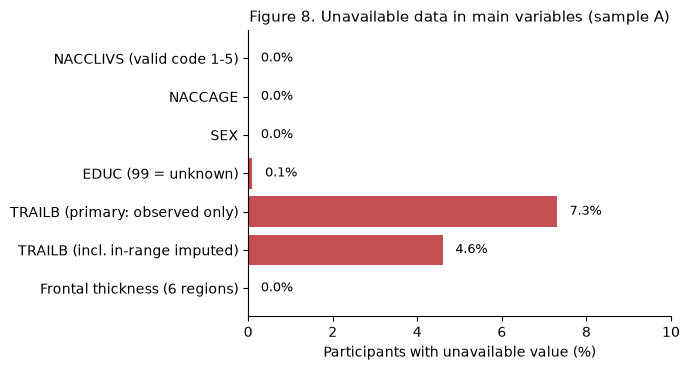

In [19]:
COL = {"Alone":"#4C72B0","Spouse/partner":"#DD8452","Relative/friend":"#55A868","Group":"#C44E52"}
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, bbox_inches="tight"); plt.show(); plt.close(fig)


cnt = A.LIV_grp.value_counts().reindex(GROUPS)
fig, ax = plt.subplots(figsize=(6.2, 4))
bars = ax.bar(cnt.index, cnt.values, color=[COL[g] for g in cnt.index])
for b, v in zip(bars, cnt.values): ax.text(b.get_x()+b.get_width()/2, v+8, f"{v}\n({100*v/cnt.sum():.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, cnt.max()*1.18); ax.set_ylabel("Number of participants"); ax.set_xlabel("Living situation (NACCLIVS)")
ax.set_title(f"Figure 1. Living situation, sample A: aged 65+ with valid NACCLIVS (n = {cnt.sum()})")
savefig(fig, "fig1_living_situation.png")


tb = A.TRAILB_obs.dropna()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].hist(tb, bins=np.arange(0, 310, 10), color="#4C72B0", edgecolor="white")
axs[0].axvline(tb.median(), color="k", ls="--", lw=1); axs[0].text(tb.median()+4, axs[0].get_ylim()[1]*0.92, f"median = {tb.median():.0f} s", fontsize=9)
axs[0].set_xlabel("Trail Making B time (seconds)"); axs[0].set_ylabel("Number of participants"); axs[0].set_title("(a) Raw scale")
axs[1].hist(tb, bins=np.logspace(np.log10(tb.min()), np.log10(300), 26), color="#55A868", edgecolor="white")
axs[1].set_xscale("log"); axs[1].set_xticks([30, 50, 100, 200, 300]); axs[1].set_xticklabels(["30","50","100","200","300"]); axs[1].minorticks_off(); axs[1].set_xlabel("Trail Making B time (seconds, log scale)"); axs[1].set_ylabel("Number of participants"); axs[1].set_title("(b) Log scale")
fig.suptitle(f"Figure 2. TRAILB, observed values (n = {len(tb)}; {int(A.TRAILB_at_cap.sum())} at the 300 s limit)", y=1.02, fontsize=11)
savefig(fig, "fig2_trailb_hist.png")


fig, ax = plt.subplots(figsize=(6.8, 4.2))
data = [A.loc[A.LIV_grp==g, "TRAILB_obs"].dropna().values for g in GROUPS]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, flierprops=dict(marker="o", markersize=3, alpha=.5))
for patch, g in zip(bp["boxes"], GROUPS): patch.set_facecolor(COL[g]); patch.set_alpha(.7)
for m_ in bp["medians"]: m_.set_color("k")
ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{g}\n(n = {len(x)})" for g, x in zip(GROUPS, data)])
ax.set_ylim(0, 320); ax.set_ylabel("Trail Making B time (seconds)"); ax.set_xlabel("Living situation (NACCLIVS)")
ax.set_title("Figure 3. TRAILB by living situation (descriptive)")
savefig(fig, "fig3_trailb_by_living.png")


ft_ = A.FRONTAL_THK.dropna()
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.hist(ft_, bins=30, color="#8172B2", edgecolor="white")
ax.axvline(ft_.mean(), color="k", ls="--", lw=1); ax.text(ft_.mean()-0.02, ax.get_ylim()[1]*0.92, f"mean = {ft_.mean():.2f} mm", fontsize=9, ha="right")
ax.set_xlabel("Mean cortical thickness, 6 frontal values (mm)"); ax.set_ylabel("Number of participants")
ax.set_title(f"Figure 4. Frontal cortical thickness composite (n = {len(ft_)})")
savefig(fig, "fig4_frontal_thickness_hist.png")


fig, ax = plt.subplots(figsize=(6.8, 4.2))
data = [A.loc[A.LIV_grp==g, "FRONTAL_THK"].dropna().values for g in GROUPS]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, flierprops=dict(marker="o", markersize=3, alpha=.5))
for patch, g in zip(bp["boxes"], GROUPS): patch.set_facecolor(COL[g]); patch.set_alpha(.7)
for m_ in bp["medians"]: m_.set_color("k")
ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{g}\n(n = {len(x)})" for g, x in zip(GROUPS, data)])
ax.set_ylabel("Mean frontal cortical thickness (mm)"); ax.set_xlabel("Living situation (NACCLIVS)")
ax.set_title("Figure 5. Frontal thickness by living situation (descriptive)")
savefig(fig, "fig5_thickness_by_living.png")


sub = A[["FRONTAL_THK","TRAILB_obs"]].dropna()
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(sub.FRONTAL_THK, sub.TRAILB_obs, s=12, alpha=.45, color="#4C72B0")
ax.set_yscale("log"); ax.set_yticks([30, 60, 100, 200, 300]); ax.set_yticklabels(["30","60","100","200","300"])
ax.set_xlabel("Mean frontal cortical thickness (mm)"); ax.set_ylabel("Trail Making B time (seconds, log scale)")
ax.set_title(f"Figure 6. TRAILB vs frontal thickness (n = {len(sub)})")
savefig(fig, "fig6_scatter_trailb_thickness.png")


fig, ax = plt.subplots(figsize=(6.8, 4.2))
data = [A.loc[A.LIV_grp==g, "NACCAGE"].values for g in GROUPS]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, flierprops=dict(marker="o", markersize=3, alpha=.5))
for patch, g in zip(bp["boxes"], GROUPS): patch.set_facecolor(COL[g]); patch.set_alpha(.7)
for m_ in bp["medians"]: m_.set_color("k")
ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{g}\n(n = {len(x)})" for g, x in zip(GROUPS, data)])
ax.set_ylabel("Age (years)"); ax.set_xlabel("Living situation (NACCLIVS)")
ax.set_title("Figure 7. Age by living situation (descriptive)")
savefig(fig, "fig7_age_by_living.png")


m8 = mt[["variable","pct_A"]].iloc[:7].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(m8.variable, m8.pct_A, color="#C44E52")
for i, v in enumerate(m8.pct_A): ax.text(v+0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, max(10, m8.pct_A.max()*1.25)); ax.set_xlabel("Participants with unavailable value (%)")
ax.set_title("Figure 8. Unavailable data in main variables (sample A)")
savefig(fig, "fig8_missingness.png")

In [20]:
rows = []
for g in GROUPS:
    a = A[A.LIV_grp == g]; tb = a.TRAILB_obs.dropna()
    rows.append({"group": g, "n": len(a), "age_mean": a.NACCAGE.mean(), "age_sd": a.NACCAGE.std(), "pct_female": 100*(a.SEX==2).mean(),
                 "educ_median": a.EDUC_c.median(), "pct_MCI": 100*(a.NACCUDSD==3).mean(), "pct_dementia": 100*(a.NACCUDSD==4).mean(),
                 "TRAILB_n": len(tb), "TRAILB_median": tb.median(), "TRAILB_Q1": tb.quantile(.25), "TRAILB_Q3": tb.quantile(.75),
                 "TRAILB_mean": tb.mean(), "TRAILB_sd": tb.std(), "pct_TRAILB_at_300": 100*(tb==300).mean(),
                 "THK_n": a.FRONTAL_THK.notna().sum(), "THK_mean": a.FRONTAL_THK.mean(), "THK_sd": a.FRONTAL_THK.std()})
gc = pd.DataFrame(rows).round(2)
save_tab(gc, "table_group_comparison")
R["group_comparison"] = gc.set_index("group").to_dict(orient="index")
gc.set_index("group").T

group,Alone,Spouse/partner,Relative/friend,Group
n,195.00,574.00,56.00,36.00
age_mean,72.79,72.11,71.80,71.72
age_sd,5.82,5.02,5.93,5.81
pct_female,77.95,48.08,80.36,52.78
educ_median,16.00,16.00,14.00,16.00
pct_MCI,18.46,25.78,17.86,25.00
pct_dementia,2.56,12.54,10.71,13.89
TRAILB_n,185.00,529.00,50.00,34.00
TRAILB_median,85.00,79.00,98.00,94.00
TRAILB_Q1,64.00,62.00,67.50,82.50


In [21]:
ct = pd.crosstab(A.LIV_grp, A.DX, normalize="index").mul(100).round(1).reindex(GROUPS)[["Normal","Impaired-not-MCI","MCI","Dementia"]]
save_tab(ct.reset_index(), "table_living_by_diagnosis_pct")
cn = pd.crosstab(A.LIV_grp, A.DX).reindex(GROUPS)[["Normal","Impaired-not-MCI","MCI","Dementia"]]
cp = cn.div(cn.sum(axis=1), axis=0) * 100
tab_nd = cn.astype(int).astype(str) + " (" + cp.round(1).astype(str) + "%)"
tab_nd["Total"] = cn.sum(axis=1)
save_tab(tab_nd.reset_index().rename(columns={"LIV_grp":"living situation"}), "table_living_by_diagnosis_n_pct")
tab_nd

DX,Normal,Impaired-not-MCI,MCI,Dementia,Total
LIV_grp,,,,,
Alone,154 (79.0%),0 (0.0%),36 (18.5%),5 (2.6%),195
Spouse/partner,348 (60.6%),6 (1.0%),148 (25.8%),72 (12.5%),574
Relative/friend,40 (71.4%),0 (0.0%),10 (17.9%),6 (10.7%),56
Group,22 (61.1%),0 (0.0%),9 (25.0%),5 (13.9%),36


In [22]:
J = A[["TRAILB_obs","FRONTAL_THK"]].dropna()
js = pd.DataFrame({"TRAILB (s)": qsummary(J.TRAILB_obs), "Frontal thickness (mm)": qsummary(J.FRONTAL_THK)}).T
js.insert(0, "n_both", len(J))
save_tab(js.round(3).reset_index().rename(columns={"index":"variable"}), "table_joint_summary")
R["n_joint"] = len(J)

reg = A[FRONT_COLS].describe().T[["count","mean","std","min","50%","max"]].round(3)
save_tab(reg.reset_index().rename(columns={"index":"variable"}), "table_frontal_regions_sampleA")
print(js.round(2).to_string()); reg

                        n_both      n  n_unavailable    mean     sd    min     Q1  median      Q3    max    IQR  skewness  n_outliers_1.5IQR
TRAILB (s)                 798  798.0            0.0  102.34  63.51  28.00  63.00   82.00  113.75  300.0  50.75      1.97               69.0
Frontal thickness (mm)     798  798.0            0.0    2.38   0.12   1.04   2.32    2.39    2.45    2.8   0.13     -2.67               14.0


,count,mean,std,min,50%,max
LH_CAUDALMIDDLEFRONTAL_AVGTH,861.0,2.398,0.154,0.880,2.416,2.830
LH_ROSTRALMIDDLEFRONTAL_AVGTH,861.0,2.278,0.125,1.571,2.281,2.798
LH_SUPERIORFRONTAL_AVGTH,861.0,2.484,0.142,1.124,2.490,2.903
RH_CAUDALMIDDLEFRONTAL_AVGTH,861.0,2.386,0.156,0.772,2.396,2.810
RH_ROSTRALMIDDLEFRONTAL_AVGTH,861.0,2.260,0.150,0.746,2.262,3.064
RH_SUPERIORFRONTAL_AVGTH,861.0,2.469,0.137,1.119,2.476,2.912


In [23]:
REG_SHORT = {"CAUDALMIDDLEFRONTAL":"caudal MF", "ROSTRALMIDDLEFRONTAL":"rostral MF", "SUPERIORFRONTAL":"superior F"}
def lab(c):
    h, rest = c.split("_", 1); reg, meas = rest.rsplit("_", 1)
    return f"{h} {REG_SHORT[reg]} {'thick' if meas=='AVGTH' else 'vol'}"
TH_COLS  = FRONT_COLS                                           
VOL_COLS = [c.replace("_AVGTH", "_GVOL") for c in TH_COLS]     
MRI12 = TH_COLS + VOL_COLS
A["TRAILA_class"] = classify_trail(A.TRAILA, 150)
A["TRAILA_obs"] = A.TRAILA.where(A.TRAILA_class.isin(["observed", "observed_at_cap"]))
E = A[MRI12 + ["TRAILA_obs", "TRAILB_obs", "EDUC_c", "NACCAGE"]].copy()
E.columns = [lab(c) for c in MRI12] + ["TRAILA", "TRAILB", "EDUC", "AGE"]
R["gvol_frontal_min"] = float(A[VOL_COLS].min().min()); R["gvol_frontal_max"] = float(A[VOL_COLS].max().max())
print("n:", len(E), "| complete rows:", int(E.dropna().shape[0]), "| frontal GVOL range:", R["gvol_frontal_min"], "-", R["gvol_frontal_max"])
rho = E.corr(method="spearman")
save_tab(rho.round(3).reset_index().rename(columns={"index":"variable"}), "table_exploratory_spearman_matrix")
save_tab(E.corr(method="pearson").round(3).reset_index().rename(columns={"index":"variable"}), "table_exploratory_pearson_matrix")
rho.round(2)

n: 861 | complete rows: 795 | frontal GVOL range: 277.0 - 43087.0


,LH caudal MF thick,LH rostral MF thick,LH superior F thick,RH caudal MF thick,RH rostral MF thick,RH superior F thick,LH caudal MF vol,LH rostral MF vol,LH superior F vol,RH caudal MF vol,RH rostral MF vol,RH superior F vol,TRAILA,TRAILB,EDUC,AGE
LH caudal MF thick,1.00,0.60,0.68,0.69,0.46,0.60,0.27,0.18,0.18,0.23,0.18,0.18,-0.09,-0.10,-0.09,-0.19
LH rostral MF thick,0.60,1.00,0.74,0.56,0.72,0.68,0.07,0.20,0.16,0.08,0.14,0.15,-0.00,-0.04,-0.05,-0.04
LH superior F thick,0.68,0.74,1.00,0.67,0.63,0.86,0.07,0.13,0.15,0.07,0.10,0.11,-0.07,-0.08,-0.05,-0.14
RH caudal MF thick,0.69,0.56,0.67,1.00,0.57,0.67,0.18,0.19,0.20,0.29,0.19,0.20,-0.09,-0.12,-0.05,-0.11
RH rostral MF thick,0.46,0.72,0.63,0.57,1.00,0.69,0.05,0.15,0.19,0.07,0.20,0.18,-0.08,-0.08,0.01,0.00
RH superior F thick,0.60,0.68,0.86,0.67,0.69,1.00,0.02,0.10,0.14,0.05,0.10,0.13,-0.06,-0.09,0.01,-0.06
LH caudal MF vol,0.27,0.07,0.07,0.18,0.05,0.02,1.00,0.60,0.58,0.66,0.62,0.62,-0.19,-0.14,0.10,-0.10
LH rostral MF vol,0.18,0.20,0.13,0.19,0.15,0.10,0.60,1.00,0.69,0.56,0.79,0.71,-0.19,-0.14,0.13,-0.11
LH superior F vol,0.18,0.16,0.15,0.20,0.19,0.14,0.58,0.69,1.00,0.56,0.67,0.86,-0.19,-0.18,0.16,-0.11
RH caudal MF vol,0.23,0.08,0.07,0.29,0.07,0.05,0.66,0.56,0.56,1.00,0.53,0.58,-0.19,-0.15,0.07,-0.12


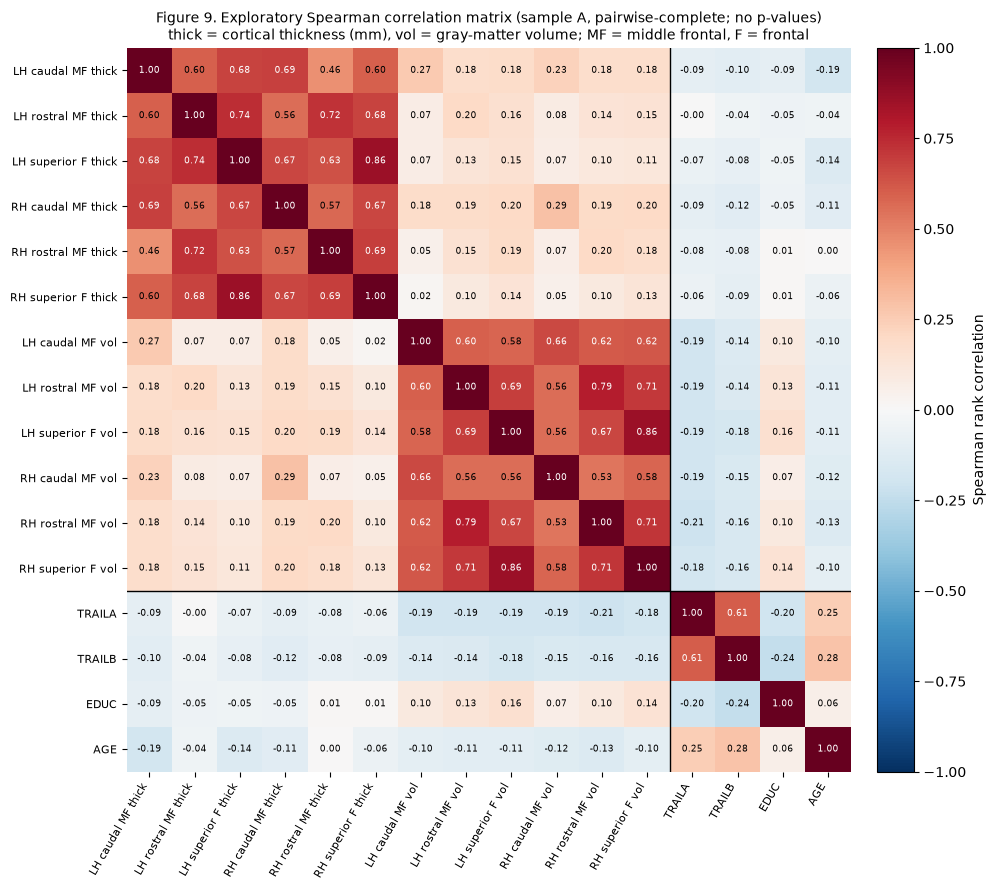

         comparison             pair  rho
thickness vs volume     LH caudal MF 0.27
thickness vs volume    LH rostral MF 0.20
thickness vs volume    LH superior F 0.15
thickness vs volume     RH caudal MF 0.29
thickness vs volume    RH rostral MF 0.20
thickness vs volume    RH superior F 0.13
           LH vs RH  caudal MF thick 0.69
           LH vs RH    caudal MF vol 0.66
           LH vs RH rostral MF thick 0.72
           LH vs RH   rostral MF vol 0.79
           LH vs RH superior F thick 0.86
           LH vs RH   superior F vol 0.86


,TRAILB,TRAILA,AGE,EDUC
LH caudal MF thick,-0.10,-0.09,-0.19,-0.09
LH rostral MF thick,-0.04,-0.00,-0.04,-0.05
LH superior F thick,-0.08,-0.07,-0.14,-0.05
RH caudal MF thick,-0.12,-0.09,-0.11,-0.05
RH rostral MF thick,-0.08,-0.08,0.00,0.01
RH superior F thick,-0.09,-0.06,-0.06,0.01
LH caudal MF vol,-0.14,-0.19,-0.10,0.10
LH rostral MF vol,-0.14,-0.19,-0.11,0.13
LH superior F vol,-0.18,-0.19,-0.11,0.16
RH caudal MF vol,-0.15,-0.19,-0.12,0.07


In [24]:
names = list(rho.columns)
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        v = rho.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > .6 else "black")
ax.axhline(11.5, color="k", lw=1); ax.axvline(11.5, color="k", lw=1)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Spearman rank correlation")
ax.set_title("Figure 9. Exploratory Spearman correlation matrix (sample A, pairwise-complete; no p-values)\nthick = cortical thickness (mm), vol = gray-matter volume; MF = middle frontal, F = frontal", fontsize=10)
savefig(fig, "fig9_correlation_matrix.png")


rows = []
for h in ("LH", "RH"):
    for r in FRONT:
        t, v = f"{h}_{r}_AVGTH", f"{h}_{r}_GVOL"
        rows.append({"comparison": "thickness vs volume", "pair": f"{h} {REG_SHORT[r]}", "rho": A[t].corr(A[v], method="spearman")})
for r in FRONT:
    for meas in ("AVGTH", "GVOL"):
        rows.append({"comparison": "LH vs RH", "pair": f"{REG_SHORT[r]} {'thick' if meas=='AVGTH' else 'vol'}", "rho": A[f"LH_{r}_{meas}"].corr(A[f"RH_{r}_{meas}"], method="spearman")})
pairs = pd.DataFrame(rows); pairs["rho"] = pairs.rho.round(2)
save_tab(pairs, "table_exploratory_pairs"); print(pairs.to_string(index=False))


tab = pd.DataFrame({"TRAILB": rho.loc[names[:12], "TRAILB"], "TRAILA": rho.loc[names[:12], "TRAILA"],
                    "AGE": rho.loc[names[:12], "AGE"], "EDUC": rho.loc[names[:12], "EDUC"]}).round(2)
save_tab(tab.reset_index().rename(columns={"index":"MRI variable"}), "table_exploratory_mri_vs_others")
R["rho_mri_trailb_range"] = [float(tab.TRAILB.min()), float(tab.TRAILB.max())]
R["rho_mri_age_range"] = [float(tab.AGE.min()), float(tab.AGE.max())]
R["rho_mri_educ_range"] = [float(tab.EDUC.min()), float(tab.EDUC.max())]
R["rho_trailA_trailB"] = float(rho.loc["TRAILA","TRAILB"]); R["rho_age_trailB"] = float(rho.loc["AGE","TRAILB"]); R["rho_educ_trailB"] = float(rho.loc["EDUC","TRAILB"])
tab

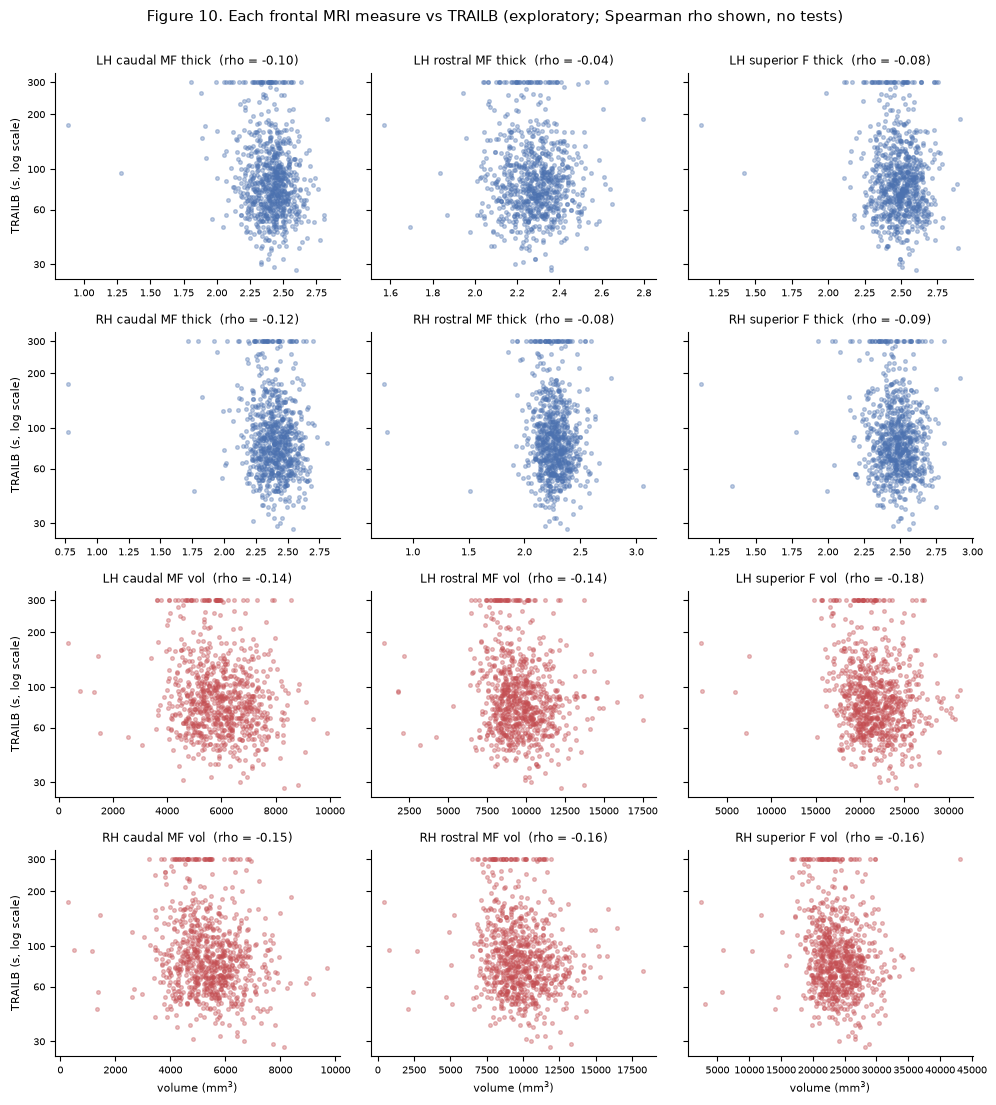

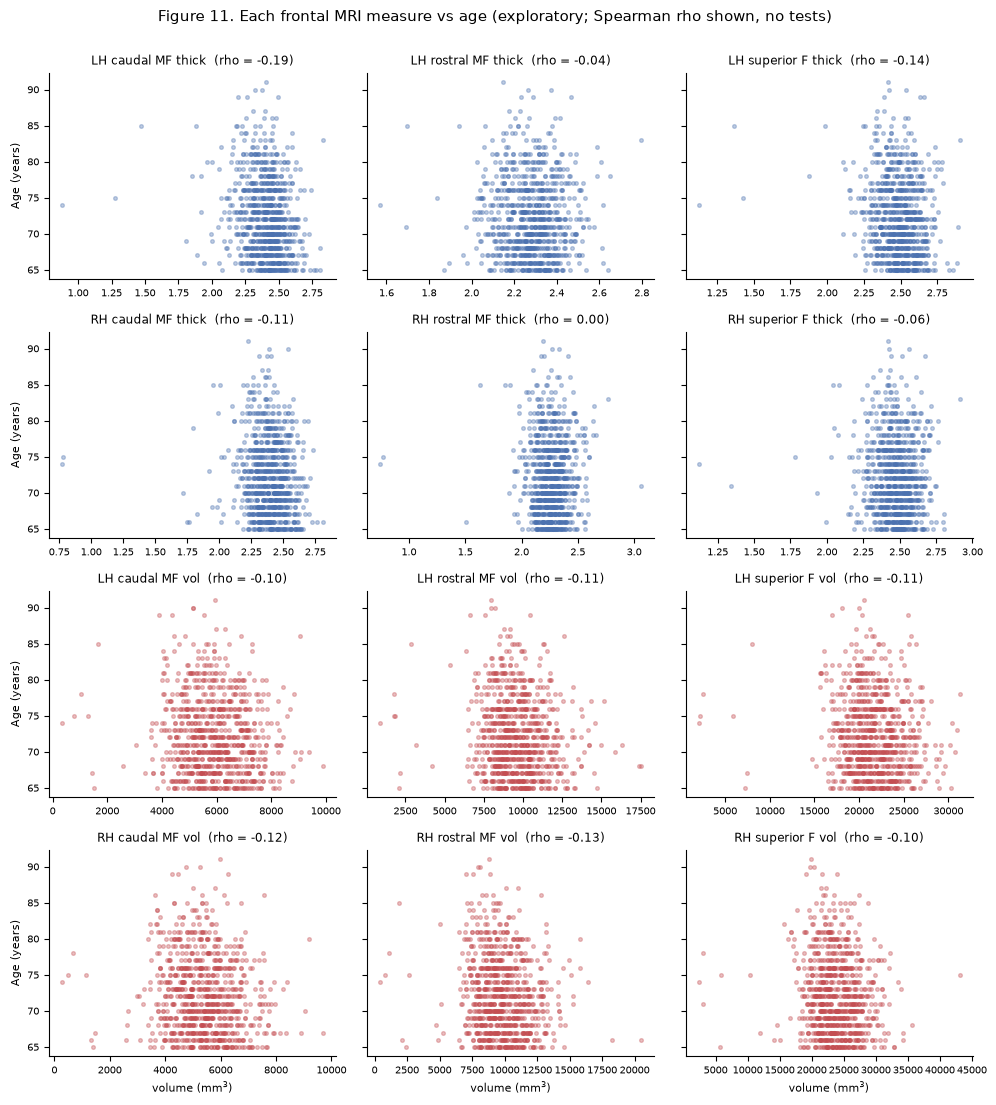

In [25]:
GRID = [[f"{h}_{r}_{m}" for r in FRONT] for m in ("AVGTH", "GVOL") for h in ("LH", "RH")]
def grid_scatter(ycol, ylabel, name, title, logy=False, xcol_is_mri=True):
    fig, axs = plt.subplots(4, 3, figsize=(10, 11), sharey=True)
    for i, row in enumerate(GRID):
        for j, c in enumerate(row):
            ax = axs[i, j]; sub = A[[c, ycol]].dropna()
            ax.scatter(sub[c], sub[ycol], s=7, alpha=.35, color="#4C72B0" if "AVGTH" in c else "#C44E52")
            r_ = sub[c].corr(sub[ycol], method="spearman")
            ax.set_title(f"{lab(c)}  (rho = {r_:.2f})", fontsize=8.5)
            if logy: ax.set_yscale("log"); ax.set_yticks([30, 60, 100, 200, 300]); ax.set_yticklabels(["30","60","100","200","300"]); ax.minorticks_off()
            ax.tick_params(labelsize=7)
            if i == 3: ax.set_xlabel(r"volume (mm$^3$)" if "GVOL" in c else "thickness (mm)", fontsize=8)
            if j == 0: ax.set_ylabel(ylabel, fontsize=8)
    fig.suptitle(title, fontsize=10.5, y=1.0); savefig(fig, name)
grid_scatter("TRAILB_obs", "TRAILB (s, log scale)", "fig10_mri_vs_trailb.png",
             "Figure 10. Each frontal MRI measure vs TRAILB (exploratory; Spearman rho shown, no tests)", logy=True)
grid_scatter("NACCAGE", "Age (years)", "fig11_mri_vs_age.png",
             "Figure 11. Each frontal MRI measure vs age (exploratory; Spearman rho shown, no tests)")

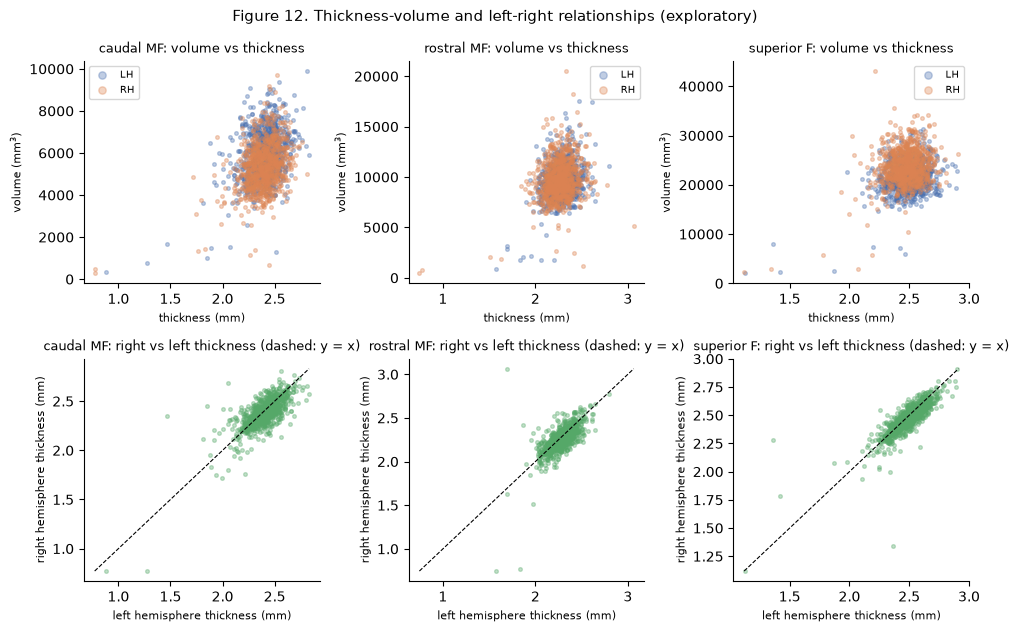

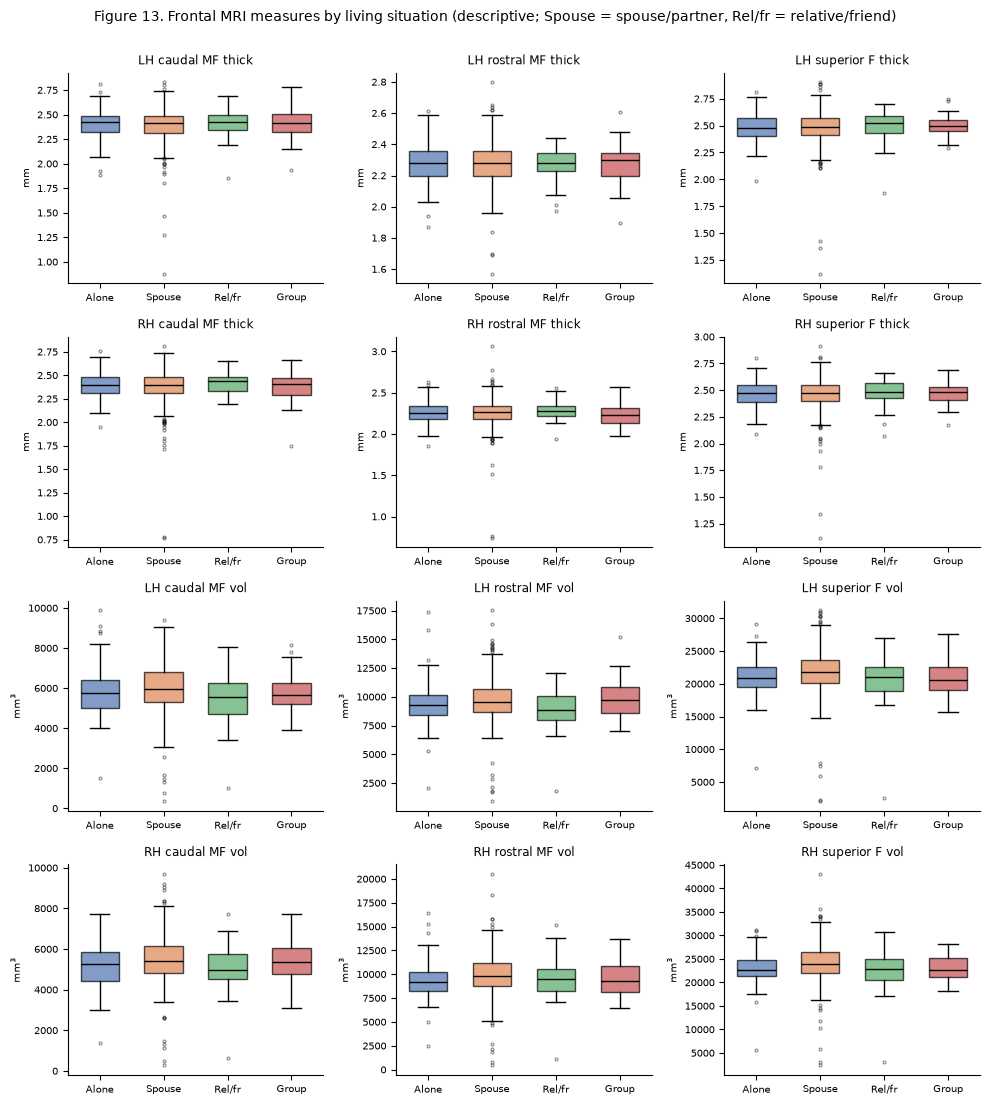

LIV_grp,Alone,Spouse/partner,Relative/friend,Group
LH caudal MF thick,2.42,2.41,2.43,2.42
LH rostral MF thick,2.28,2.28,2.28,2.30
LH superior F thick,2.48,2.49,2.52,2.50
RH caudal MF thick,2.40,2.39,2.43,2.40
RH rostral MF thick,2.25,2.26,2.28,2.23
RH superior F thick,2.47,2.48,2.48,2.48
LH caudal MF vol,5768.00,5974.50,5534.00,5671.00
LH rostral MF vol,9267.00,9575.50,8891.00,9702.50
LH superior F vol,20927.00,21757.00,21003.50,20601.50
RH caudal MF vol,5242.00,5428.50,4980.00,5364.00


In [26]:
fig, axs = plt.subplots(2, 3, figsize=(10, 6.4))
for j, r in enumerate(FRONT):
    ax = axs[0, j]
    for h, colr in (("LH", "#4C72B0"), ("RH", "#DD8452")):
        ax.scatter(A[f"{h}_{r}_AVGTH"], A[f"{h}_{r}_GVOL"], s=7, alpha=.35, color=colr, label=h)
    ax.set_title(f"{REG_SHORT[r]}: volume vs thickness", fontsize=9); ax.set_xlabel("thickness (mm)", fontsize=8); ax.set_ylabel(r"volume (mm$^3$)", fontsize=8); ax.legend(fontsize=7, markerscale=2)
    ax = axs[1, j]
    ax.scatter(A[f"LH_{r}_AVGTH"], A[f"RH_{r}_AVGTH"], s=7, alpha=.35, color="#55A868")
    lo, hi = A[[f"LH_{r}_AVGTH", f"RH_{r}_AVGTH"]].min().min(), A[[f"LH_{r}_AVGTH", f"RH_{r}_AVGTH"]].max().max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=.8); ax.set_title(f"{REG_SHORT[r]}: right vs left thickness (dashed: y = x)", fontsize=9)
    ax.set_xlabel("left hemisphere thickness (mm)", fontsize=8); ax.set_ylabel("right hemisphere thickness (mm)", fontsize=8)
fig.suptitle("Figure 12. Thickness-volume and left-right relationships (exploratory)", fontsize=10.5)
savefig(fig, "fig12_thickness_volume_lr.png")


fig, axs = plt.subplots(4, 3, figsize=(10, 11))
for i, row in enumerate(GRID):
    for j, c in enumerate(row):
        ax = axs[i, j]; data = [A.loc[A.LIV_grp==g, c].dropna().values for g in GROUPS]
        bp = ax.boxplot(data, patch_artist=True, widths=.6, flierprops=dict(marker="o", markersize=2, alpha=.4))
        for patch, g in zip(bp["boxes"], GROUPS): patch.set_facecolor(COL[g]); patch.set_alpha(.7)
        for m_ in bp["medians"]: m_.set_color("k")
        ax.set_xticks(range(1, 5)); ax.set_xticklabels(["Alone","Spouse","Rel/fr","Group"], fontsize=7, rotation=0)
        ax.set_title(lab(c), fontsize=8.5); ax.tick_params(labelsize=7)
        ax.set_ylabel("mm" if "AVGTH" in c else r"mm$^3$", fontsize=7.5)
fig.suptitle("Figure 13. Frontal MRI measures by living situation (descriptive; Spouse = spouse/partner, Rel/fr = relative/friend)", fontsize=10, y=1.0)
savefig(fig, "fig13_mri_by_living.png")


med = A.groupby("LIV_grp")[MRI12].median().reindex(GROUPS).T; med.index = [lab(c) for c in med.index]
save_tab(med.round(3).reset_index().rename(columns={"index":"MRI variable"}), "table_exploratory_mri_median_by_living")
med.round(2)

In [27]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
with open(TAB / "key_numbers.json", "w") as f: json.dump(_clean(R), f, indent=1, default=str)
print("Saved", len(R), "key numbers;", len(list(FIG.glob('*.png'))), "figures;", len(list(TAB.glob('*.csv'))), "tables")

Saved 47 key numbers; 13 figures; 29 tables
